In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
from PIL import Image
import os

IMG_WIDTH = 512
IMG_HEIGHT = 512
IMG_SIZE= 512
IMG_CHANNELS = 3

X_train = []
Y_train = []

image_path = "/content/drive/MyDrive/New/rimages/"
mask_path = "/content/drive/MyDrive/New/rmasks/"

In [ ]:
X_train = []
Y_train = []

for file in os.listdir(image_path):

    img = Image.open(image_path + file).resize((IMG_SIZE, IMG_SIZE))
    img = np.array(img)

    # Convert mask to grayscale (single channel) and add channel dimension
    mask = Image.open(mask_path + file).convert('L').resize((IMG_SIZE, IMG_SIZE)) # 'L' mode for grayscale
    mask = np.array(mask)
    mask = np.expand_dims(mask, axis=-1) # Shape will be (128, 128, 1)

    X_train.append(img)
    Y_train.append(mask)

In [ ]:
X_train = np.array(X_train)
Y_train = np.array(Y_train)

In [ ]:
Y_train = (Y_train > 127).astype("float32")

In [ ]:
print(np.unique(Y_train))

[0. 1.]


In [ ]:
print("X_train shape:", X_train.shape)
print("Y_train shape:", Y_train.shape)

X_train shape: (39, 512, 512, 3)
Y_train shape: (39, 512, 512, 1)


In [ ]:
def down_block(x, filters, kernel_size=(3, 3), padding="same", strides=1):
    c = keras.layers.Conv2D(filters, kernel_size, padding=padding, strides=strides, activation="relu")(x)
    c = keras.layers.Conv2D(filters, kernel_size, padding=padding, strides=strides, activation="relu")(c)
    p = keras.layers.MaxPool2D((2, 2), (2, 2))(c)
    return c, p

def up_block(x, skip, filters, kernel_size=(3, 3), padding="same", strides=1):
    us = keras.layers.UpSampling2D((2, 2))(x)
    concat = keras.layers.Concatenate()([us, skip])
    c = keras.layers.Conv2D(filters, kernel_size, padding=padding, strides=strides, activation="relu")(concat)
    c = keras.layers.Conv2D(filters, kernel_size, padding=padding, strides=strides, activation="relu")(c)
    return c

def bottleneck(x, filters, kernel_size=(3, 3), padding="same", strides=1):
    c = keras.layers.Conv2D(filters, kernel_size, padding=padding, strides=strides, activation="relu")(x)
    c = keras.layers.Conv2D(filters, kernel_size, padding=padding, strides=strides, activation="relu")(c)
    return c


In [ ]:
image_size = 512

In [ ]:
def UNet():
    f = [16, 32, 64, 128, 256]
    inputs = keras.layers.Input((image_size, image_size, 3))

    p0 = inputs
    c1, p1 = down_block(p0, f[0]) #128 -> 64
    c2, p2 = down_block(p1, f[1]) #64 -> 32
    c3, p3 = down_block(p2, f[2]) #32 -> 16
    c4, p4 = down_block(p3, f[3]) #16->8

    bn = bottleneck(p4, f[4])

    u1 = up_block(bn, c4, f[3]) #8 -> 16
    u2 = up_block(u1, c3, f[2]) #16 -> 32
    u3 = up_block(u2, c2, f[1]) #32 -> 64
    u4 = up_block(u3, c1, f[0]) #64 -> 128

    outputs = keras.layers.Conv2D(1, (1, 1), padding="same", activation="sigmoid")(u4)
    model = keras.models.Model(inputs, outputs)
    return model

In [ ]:
import tensorflow.keras as keras
model = UNet()
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["acc"])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 512, 512,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 512, 512,  │        448 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 512, 512,  │      2,320 │ conv2d[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 256, 256,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 256, 256,  │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 256, 256,  │      9,248 │ conv2d_2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 128, 128,  │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 128, 128,  │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 128, 128,  │     36,928 │ conv2d_4[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 64, 64,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d_2[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 64, 64,    │    147,584 │ conv2d_6[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 32, 32,    │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 32, 32,    │    295,168 │ max_pooling2d_3[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 32, 32,    │    590,080 │ conv2d_8[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 64, 64,    │          0 │ conv2d_9[0][0]    │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64, 64,    │          0 │ up_sampling2d[0]

 Total params: 1,962,625 (7.49 MB)

 Trainable params: 1,962,625 (7.49 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train,
    Y_train,
    validation_split = 0.1,
    batch_size = 2,
    epochs = 20,
    )

Epoch 1/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 47s 1s/step - acc: 0.5917 - loss: 13.7240 - val_acc: 0.7643 - val_loss: 1.4668
Epoch 2/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - acc: 0.8389 - loss: 0.8438 - val_acc: 0.9651 - val_loss: 0.1176
Epoch 3/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - acc: 0.9680 - loss: 0.0992 - val_acc: 0.9738 - val_loss: 0.0804
Epoch 4/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 77ms/step - acc: 0.9743 - loss: 0.0800 - val_acc: 0.9756 - val_loss: 0.0765
Epoch 5/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - acc: 0.9745 - loss: 0.0777 - val_acc: 0.9780 - val_loss: 0.0670
Epoch 6/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - acc: 0.9745 - loss: 0.0786 - val_acc: 0.9729 - val_loss: 0.0800
Epoch 7/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - acc: 0.9734 - loss: 0.0819 - val_acc: 0.9732 - val_loss: 0.0814
Epoch 8/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - acc: 0.9772 - loss: 0.0703 - val_acc: 0.9774 - val_loss: 0.0689
Epoch 9/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - acc: 0.9779

In [ ]:
model.save("unet_model.h5")

In [ ]:
IMG_WIDTH = 512
IMG_HEIGHT = 512
IMG_SIZE=512
IMG_CHANNELS = 3

X_test = []
Y_test = []

image_path = "/content/drive/MyDrive/New/test/images/"
mask_path = "/content/drive/MyDrive/New/test/masks/"

In [ ]:
X_test = []
Y_test = []

for file in os.listdir(image_path):

    img = Image.open(image_path + file).resize((IMG_SIZE, IMG_SIZE))
    img = np.array(img)

    # Convert mask to grayscale (single channel) and add channel dimension
    mask = Image.open(mask_path + file).convert('L').resize((IMG_SIZE, IMG_SIZE)) # 'L' mode for grayscale
    mask = np.array(mask)
    mask = np.expand_dims(mask, axis=-1) # Shape will be (128, 128, 1)

    X_test.append(img)
    Y_test.append(mask)

In [ ]:
X_test = np.array(X_test)
predictions = model.predict(X_test)

pred_masks = (predictions > 0.5).astype(np.uint8)

1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step


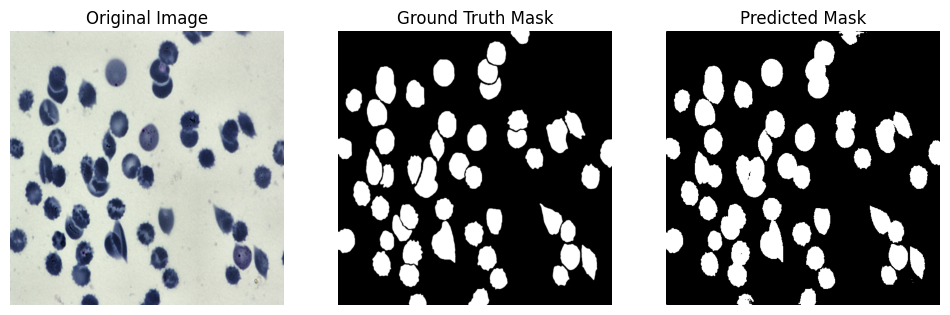

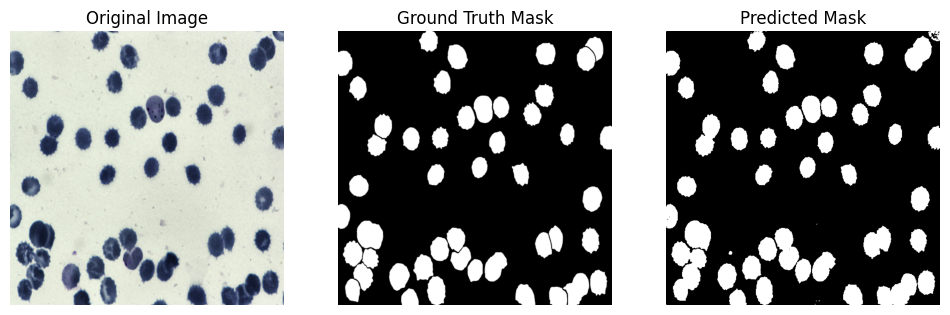

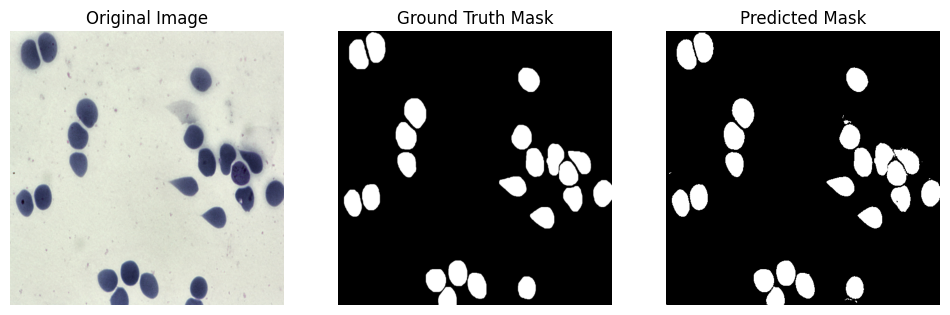

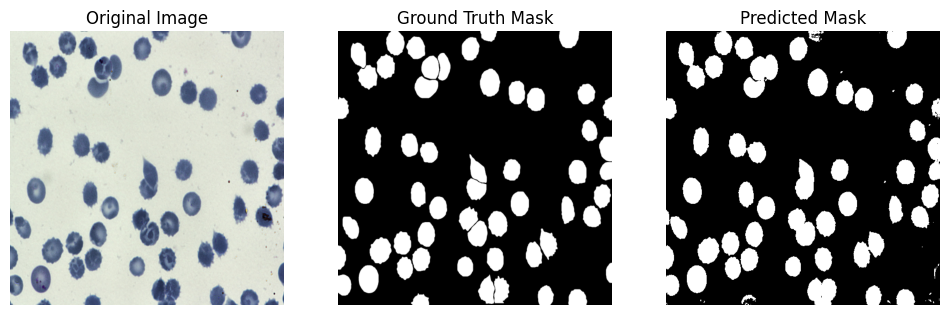

In [ ]:
import matplotlib.pyplot as plt

for i in range(len(X_test)): # Changed from range(6) to range(len(X_test))

    plt.figure(figsize=(12,4))

    plt.subplot(1,3,1)
    plt.title("Original Image")
    plt.imshow(X_test[i])
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.title("Ground Truth Mask")
    plt.imshow(Y_test[i].squeeze(), cmap="gray")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.title("Predicted Mask")
    plt.imshow(pred_masks[i].squeeze(), cmap="gray")
    plt.axis("off")

    plt.show()